In [11]:
pip install scikit-image

Note: you may need to restart the kernel to use updated packages.


In [12]:
pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


In [13]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.exposure import match_histograms

In [14]:
def generate_histogram(image):
  histogram = cv2.calcHist([image], [0], None, [256], [0, 256])
  return histogram

def perform_histogram_equalization(image):
  gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
  # Apply histogram equalization
  equalized_image = cv2.equalizeHist(gray_image)
  return equalized_image

def perform_histogram_matching(image, reference_image):
  gray_input = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
  gray_reference = cv2.cvtColor(reference_image, cv2.COLOR_BGR2GRAY)
# Calculate histograms
  input_hist = generate_histogram(gray_input)
  reference_hist = generate_histogram(gray_reference)
# Perform histogram matching
  matched_image = match_histograms(gray_input, gray_reference)
  matched_image = np.uint8(matched_image)
  return matched_image

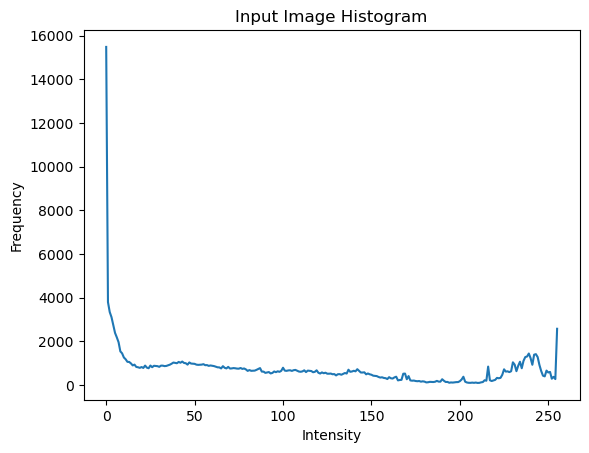

In [15]:
# Load the input image
image = cv2.imread('images/image_1.jpg')
# Generate and display the histogram of the input image
input_hist = generate_histogram(image)
plt.plot(input_hist)
plt.title("Input Image Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency")
plt.show()

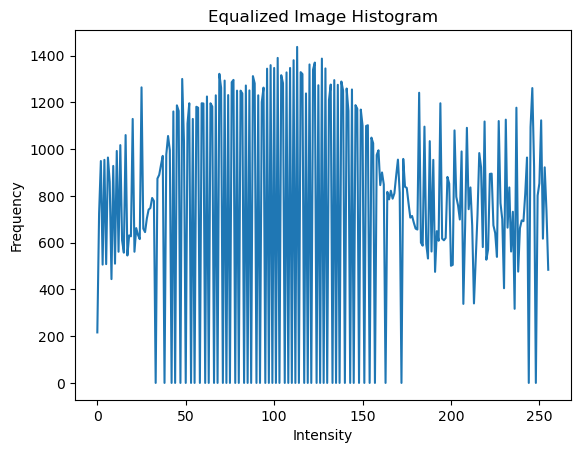

In [16]:
# Perform histogram equalization
equalized_image = perform_histogram_equalization(image)
# Generate and display the histogram of the equalized image
equalized_hist = generate_histogram(equalized_image)
plt.plot(equalized_hist)
plt.title("Equalized Image Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency")
plt.show()

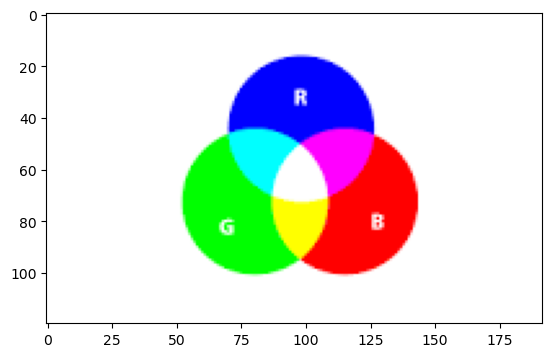

In [23]:
# Load the reference image for histogram matching

reference_image = cv2.imread('images/images.png')

plt.imshow(reference_image)



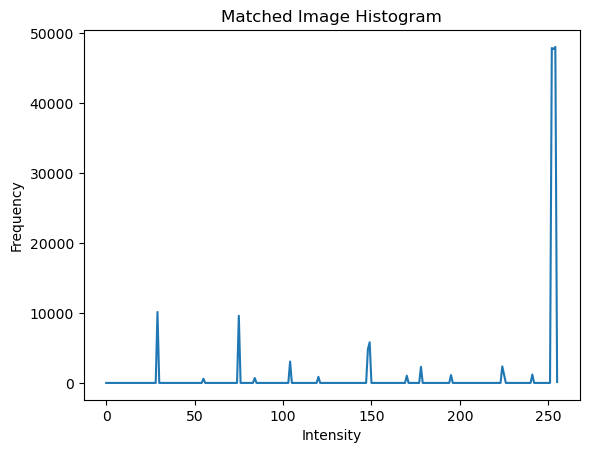

In [24]:
# Perform histogram matching
matched_image = perform_histogram_matching(image, reference_image)
# Generate and display the histogram of the matched image
matched_hist = generate_histogram(matched_image)

plt.plot(matched_hist)
plt.title("Matched Image Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency")
plt.show()

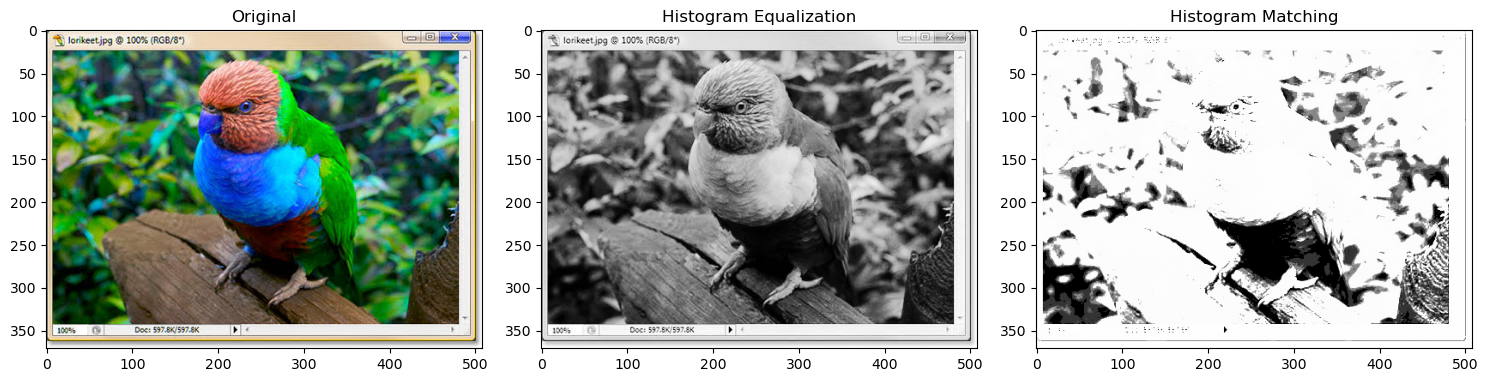

In [21]:
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(image)
plt.title("Original")

plt.subplot(1,3,2)
plt.imshow(equalized_image,cmap='gray')
plt.title("Histogram Equalization")

plt.subplot(1,3,3)
plt.imshow(matched_image,cmap='gray')
plt.title("Histogram Matching")

plt.tight_layout()
plt.show()


In [19]:
# Save the equalized and matched images 
equalized_path = 'equalized.jpg'
matched_path = 'matched.jpg'
cv2.imwrite(equalized_path, equalized_image)
cv2.imwrite(matched_path, matched_image)
print(f"Equalized image saved at: {equalized_path}")
print(f"Matched image saved at: {matched_path}")

Equalized image saved at: equalized.jpg
Matched image saved at: matched.jpg
